<p style="font-size:300%; background-color:#ffe6f0; color:#0044cc; text-align:center; line-height:80px; margin:0; padding:0;"> <b>Detección de Objetos - Segmentación de Imágenes</b> 
</p>

<p style="font-size:240%; background-color:#ffe6f0; color:#cc0000; text-align:center; line-height:60px; margin:0; padding:0;">
  <b>Inteligencia Artificial & Mini Robots</b>
</p>

<p style="font-size:200%; text-align:center; line-height:40px; margin:0;">
  <br><b>Prof. Flavio Prieto</b>
</p>

<p style="font-size:160%; text-align:center; line-height:25px; margin:0;">
  email: <a href="mailto:faprietoo@unal.edu.co">faprietoo@unal.edu.co</a>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  <br><b>DEPARTAMENTO DE INGENIERÍA MECÁNICA Y MECATRÓNICA</b>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  Facultad de Ingeniería
</p>

<p style="font-size:160%; text-align:center; line-height:30px; margin:0;">
  Universidad Nacional de Colombia – Sede Bogotá
</p>

<div style="text-align:center; margin-top:20px; margin-bottom:10px;">
  <img src="Fig/Escudo_UN.png" alt="Escudo UNAL" width="90" style="border:none;">
</div>


<div style="border: 2px solid #4CAF50; padding: 5px; border-radius: 4px; background-color: #e8f5e9; text-align: center;">
</div>

# **Detección de Objetos**

## Métodos clásicos

In [1]:
# ------------------------------------------------------------
# DEMOSTRACIÓN DE TÉCNICAS CLÁSICAS DE DETECCIÓN DE OBJETOS
# Sliding Window + Classifier | HOG + SVM | Haar Cascades
# ------------------------------------------------------------
import cv2
import numpy as np
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "C:\Users\Flavio\anaconda3\Lib\runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Users\Flavio\anaconda3\Lib\runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "C:\Users\Flavio\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\Flavio\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\Flavio\anaconda3\Lib\site

AttributeError: _ARRAY_API not found

### Sliding Window + Classifier (SVM)

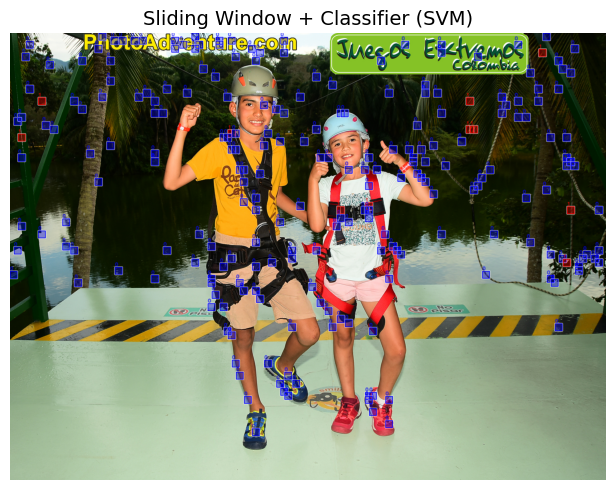

In [2]:
# ------------------------------------------------------------
# Función de sliding window
# ------------------------------------------------------------
def sliding_window(img, step=32, window_size=(64, 128)):
    """Genera regiones de la imagen en diferentes posiciones"""
    for y in range(0, img.shape[0] - window_size[1], step):
        for x in range(0, img.shape[1] - window_size[0], step):
            yield (x, y, img[y:y + window_size[1], x:x + window_size[0]])

# ------------------------------------------------------------
# Entrenar un clasificador simple HOG + SVM con datos reales
# ------------------------------------------------------------
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
X = X / 255.0

svm_clf = LinearSVC(max_iter=5000)
svm_clf.fit(X[:3000], y[:3000])

# ------------------------------------------------------------
# Cargar una imagen real
# ------------------------------------------------------------
image_path = "fig/Notebook/Foto_F1.jpg"  # Cambia esta ruta por tu imagen
img = cv2.imread(image_path)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en {image_path}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ------------------------------------------------------------
# Aplicar Sliding Window sobre la imagen real
# ------------------------------------------------------------
result = img.copy()
overlay = img.copy()   # Capa semitransparente
alpha = 0.35           # Nivel de transparencia
win_size = (28, 28)

for (x, y, patch) in sliding_window(gray, step=16, window_size=win_size):
    patch_resized = cv2.resize(patch, (28, 28)).reshape(1, -1) / 255.0
    pred = svm_clf.predict(patch_resized)[0]
    
    # Selección de color según la clase detectada
    if pred == '0':
        color = (255, 0, 0)  # Azul BGR
    elif pred == '1':
        color = (0, 0, 255)  # Rojo BGR
    else:
        continue  # Ignorar clases no relevantes

    # --- Dibujar resaltado visual ---
    # Rectángulo semitransparente
    cv2.rectangle(overlay, (x, y), (x + win_size[0], y + win_size[1]), color, -1)
    
    # Doble borde para contraste (blanco + color)
    cv2.rectangle(result, (x-1, y-1), (x + win_size[0]+1, y + win_size[1]+1), (255, 255, 255), 3)
    cv2.rectangle(result, (x, y), (x + win_size[0], y + win_size[1]), color, 2)

    # Etiqueta con clase
    cv2.putText(result, f"{pred}", (x, y - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

# Mezcla overlay con transparencia
cv2.addWeighted(overlay, alpha, result, 1 - alpha, 0, result)

# ------------------------------------------------------------
# Mostrar resultados
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.title("Sliding Window + Classifier (SVM)", fontsize=14)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.tight_layout()
plt.show()


### HOG + SVM

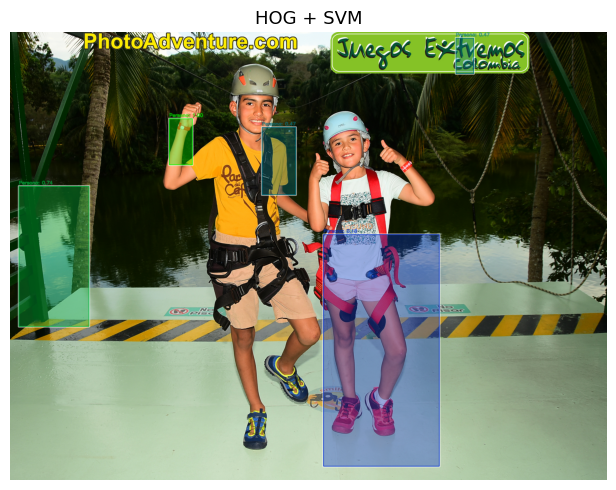

In [3]:
# ------------------------------------------------------------
# Ejemplo: HOG + SVM (Dalal & Triggs)
# ------------------------------------------------------------

# Cargar imagen de persona
img = cv2.imread(cv2.samples.findFile("fig/Notebook/Foto_F1.jpg"))
if img is None:
    raise FileNotFoundError("No se encontró la imagen especificada.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detector de personas basado en HOG + SVM
hog_detector = cv2.HOGDescriptor()
hog_detector.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())

# Detección
(rects, weights) = hog_detector.detectMultiScale(
    gray, winStride=(8,8), padding=(8,8), scale=1.05
)

# Copias para mezcla con transparencia
result = img.copy()
overlay = img.copy()
alpha = 0.35  # Nivel de transparencia

# ------------------------------------------------------------
# Dibujar detecciones resaltadas
# ------------------------------------------------------------
for i, (x, y, w, h) in enumerate(rects):
    # Acceso seguro a la confianza
    conf = float(weights[i]) if len(weights) > i else 0.0
    conf = np.clip(conf, 0, 1)  # Limita entre [0, 1]

    # Ignorar detecciones muy débiles
    if conf < 0.1:
        continue

    # Color según confianza (rojo → verde)
    color = (
        int(255 * (1 - conf)),   # R
        int(255 * conf),         # G
        0                        # B
    )

    # Relleno semitransparente
    cv2.rectangle(overlay, (x, y), (x + w, y + h), color, -1)

    # Doble borde: blanco + color
    cv2.rectangle(result, (x - 2, y - 2), (x + w + 2, y + h + 2), (255, 255, 255), 3)
    cv2.rectangle(result, (x, y), (x + w, y + h), color, 2)

    # Texto con confianza
    label = f"Persona: {conf:.2f}"
    cv2.putText(result, label, (x, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

# Mezclar overlay con transparencia
cv2.addWeighted(overlay, alpha, result, 1 - alpha, 0, result)

# ------------------------------------------------------------
# Mostrar resultado
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.title("HOG + SVM", fontsize=13)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.tight_layout()
plt.show()


### Haar Cascades (Viola–Jones)

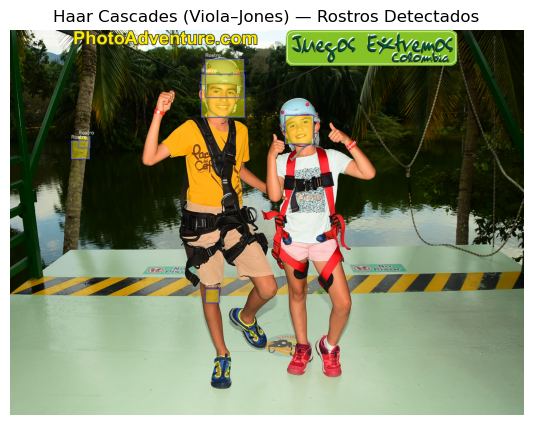

In [4]:
# ------------------------------------------------------------
# Ejemplo: Haar Cascades (Viola–Jones)
# ------------------------------------------------------------
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Cargar imagen
img_path = "fig/Notebook/Foto_F1.jpg"
img2 = cv2.imread(cv2.samples.findFile(img_path))

# Verificar si se cargó correctamente
if img2 is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# Convertir a escala de grises
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Detección de rostros
faces = face_cascade.detectMultiScale(
    gray2, 
    scaleFactor=1.1, 
    minNeighbors=5, 
    minSize=(30, 30)
)

# Crear copia para resaltado con transparencia
overlay = img2.copy()
alpha = 0.4  # nivel de transparencia

# Dibujar rectángulos con borde grueso y relleno semitransparente
for (x, y, w, h) in faces:
    # Rectángulo de relleno semitransparente
    cv2.rectangle(overlay, (x, y), (x+w, y+h), (0, 255, 255), -1)
    # Borde más intenso
    cv2.rectangle(img2, (x, y), (x+w, y+h), (255, 0, 0), 3)
    # Etiqueta
    cv2.putText(img2, 'Rostro', (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 
                0.7, (255, 255, 255), 2, cv2.LINE_AA)

# Combinar transparencia
img_highlighted = cv2.addWeighted(overlay, alpha, img2, 1 - alpha, 0)

# Mostrar resultado
plt.figure(figsize=(10, 5))
plt.title("Haar Cascades (Viola–Jones) — Rostros Detectados")
plt.imshow(cv2.cvtColor(img_highlighted, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


## Métodos basados en aprendizaje profundo.


### YOLO v3

> Para cada detección, YOLO devuelve el vector completo con todos los parámetros en el formato:

$$[x, y, w, h, s, p(c_1), p(c_2), …, p(c_K)]$$

donde:

- $x, y$: Coordenadas del centro del bounding box.
- $w, h$: Ancho y alto del bounding box.
- $s$: Score total o confianza de la detección (combinación de confianza de objeto y clase).
- $p(c_i)$: Probabilidad asociada a cada clase del modelo YOLO (K = 80 para COCO).

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------
# Configuración de rutas
# ----------------------------------------
weights_path = "fig/Notebook/yolo/yolov3.weights"
config_path = "fig/Notebook/yolo/yolov3.cfg"
names_path = "fig/Notebook/yolo/coco.names"

# Cargar las etiquetas (clases)
with open(names_path, "r") as f:
    classes = [line.strip() for line in f.readlines()]

# Cargar la red preentrenada
net = cv2.dnn.readNet(weights_path, config_path)

# Usar backend CUDA si está disponible
# net.setPreferableBackend(cv2.dnn.DNN_BACKEND_CUDA)
# net.setPreferableTarget(cv2.dnn.DNN_TARGET_CUDA)

# Obtener las capas de salida del modelo
layer_names = net.getLayerNames()
output_layers = [layer_names[i - 1] for i in net.getUnconnectedOutLayers()]

# Colores aleatorios para cada clase
colors = np.random.uniform(0, 255, size=(len(classes), 3))

# ----------------------------------------
# Función para detección de objetos
# ----------------------------------------
def detectar_objetos(img, conf_threshold=0.5, nms_threshold=0.4):
    height, width, channels = img.shape

    # Crear el blob y pasar la imagen por la red
    blob = cv2.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB=True, crop=False)
    net.setInput(blob)
    outs = net.forward(output_layers)

    class_ids = []
    confidences = []
    boxes = []
    detecciones = []  # aquí guardaremos los vectores [x, y, w, h, s, p(c1), ..., p(cK)]

    # Procesar las detecciones
    for out in outs:
        for detection in out:
            scores = detection[5:]
            class_id = np.argmax(scores)
            confidence_class = scores[class_id]
            confidence_obj = detection[4]
            score_total = confidence_obj * confidence_class  # score global

            if score_total > conf_threshold:
                # Coordenadas del objeto detectado
                center_x = int(detection[0] * width)
                center_y = int(detection[1] * height)
                w = int(detection[2] * width)
                h = int(detection[3] * height)
                x = int(center_x - w / 2)
                y = int(center_y - h / 2)
                boxes.append([x, y, w, h])
                confidences.append(float(score_total))
                class_ids.append(class_id)

                # Guardar vector completo de salida
                fila = [center_x, center_y, w, h, float(score_total)] + scores.tolist()
                detecciones.append(fila)

    # Supresión de no-máximos (NMS) para evitar cajas duplicadas
    indexes = cv2.dnn.NMSBoxes(boxes, confidences, conf_threshold, nms_threshold)

    # Dibujar las detecciones y mostrar los parámetros
    for i in range(len(boxes)):
        if i in indexes:
            x, y, w, h = boxes[i]
            label = str(classes[class_ids[i]])
            color = colors[class_ids[i]]
            confidence = confidences[i]

            # Escalar grosor y tamaño de fuente según el ancho de la imagen
            escala = img.shape[1] / 400
            grosor_rect = max(1, int(2 * escala))
            grosor_texto = max(1, int(1 * escala))
            tam_fuente = 0.5 * escala

            # Dibujar cuadro y etiqueta
            cv2.rectangle(img, (x, y), (x + w, y + h), color, grosor_rect)
            cv2.putText(img, label, (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, tam_fuente, (255, 255, 0), grosor_texto)

    # ----------------------------------------
    # Imprimir en consola las detecciones completas
    # ----------------------------------------
    print("\n--- Parámetros de salida YOLO ---")
    for i, det in enumerate(detecciones):
        print(f"Detección {i+1}: [{', '.join([f'{v:.4f}' for v in det])}]")

    return img

# ----------------------------------------
# Detectar objetos en una imagen
# ----------------------------------------
image_path = "fig/notebook/Det_img3.jpg"  # cambia por tu imagen
img = cv2.imread(image_path)
print("Tamaño imagen: ",img.shape)


resultado = detectar_objetos(img)

Tamaño imagen:  (183, 275, 3)

--- Parámetros de salida YOLO ---
Detección 1: [83.0000, 104.0000, 49.0000, 122.0000, 0.6788, 0.8238, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]
Detección 2: [89.0000, 104.0000, 49.0000, 118.0000, 0.9949, 0.9975, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

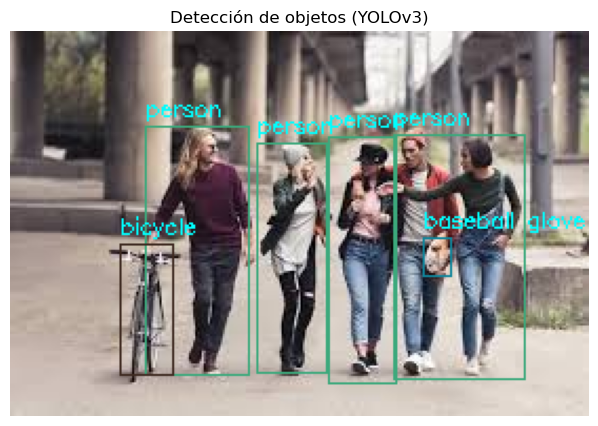

In [6]:
# Convertir de BGR a RGB para mostrar con matplotlib
resultado_rgb = cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,5))
plt.imshow(resultado_rgb)
plt.axis('off')
plt.title("Detección de objetos (YOLOv3)")
plt.show()


--- Parámetros de salida YOLO ---
Detección 1: [256.0000, 158.0000, 565.0000, 319.0000, 0.7384, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.8584, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]
Detección 2: [609.0000, 157.0000, 206.0000, 116.0000, 0.7430, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.8552, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0

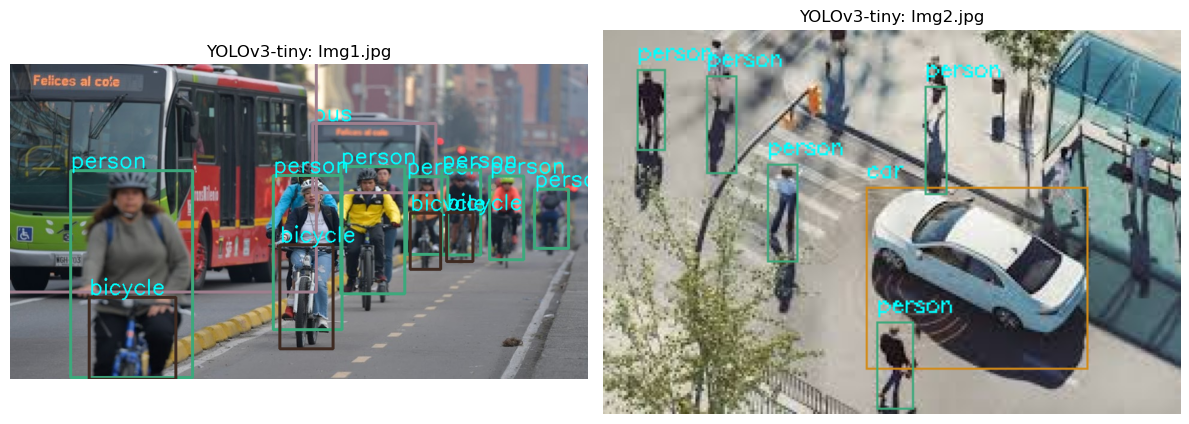

In [7]:
# ----------------------------------------
# Detectar objetos en dos imágenes
# ----------------------------------------
image_paths = ["fig/notebook/Det_img1.jpg", "fig/notebook/Det_img2.jpg"]
resultados = []

for path in image_paths:
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"No se encontró la imagen: {path}")
    resultado = detectar_objetos(img)
    resultados.append(cv2.cvtColor(resultado, cv2.COLOR_BGR2RGB))

# Mostrar resultados lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, res, title in zip(axes, resultados, ["YOLOv3-tiny: Img1.jpg", "YOLOv3-tiny: Img2.jpg"]):
    ax.imshow(res)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


### SSD

In [8]:
import torch
from torchvision import transforms
import torchvision
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------
# Configuración / utilidades
# ---------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Si deseas usar nombres de clases (ejemplo COCO - 91 clases),
# coloca aquí la lista apropiada. Si usas un modelo preentrenado en VOC,
# deberías usar la lista de clases VOC (20 clases + fondo).
# Ejemplo reducido (rellena según tu caso):
COCO_INSTANCE_CATEGORY_NAMES = [
    '__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus',
    'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign',
    'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow',
    # ... hasta 90/91 clases si usas COCO
]

# ---------------------------
# Cargar modelo SSD preentrenado
# ---------------------------
def load_model():
    try:
        # API moderna: torchvision >= 0.13 usa 'weights' o 'weights_backbone'
        model = torchvision.models.detection.ssd300_vgg16(weights='DEFAULT')
    except Exception:
        # Fallback a la forma antigua si procede
        model = torchvision.models.detection.ssd300_vgg16(pretrained=True)
    model.to(device)
    model.eval()
    return model

# ---------------------------
# Preprocesado de la imagen
# ---------------------------
preprocess = transforms.Compose([
    transforms.Resize((300, 300)),   # SSD300 espera 300x300
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ---------------------------
# Dibuja resultados sobre PIL Image
# ---------------------------
def draw_predictions(image_pil, boxes, labels, scores, score_thresh=0.5):
    draw = ImageDraw.Draw(image_pil)
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", size=14)
    except Exception:
        font = ImageFont.load_default()

    for box, lbl, scr in zip(boxes, labels, scores):
        if scr < score_thresh:
            continue
        x1, y1, x2, y2 = box
        draw.rectangle([x1, y1, x2, y2], outline="red", width=2)
        cls_name = COCO_INSTANCE_CATEGORY_NAMES[lbl] if lbl < len(COCO_INSTANCE_CATEGORY_NAMES) else str(lbl)
        text = f"{cls_name}: {scr:.2f}"
        bbox = draw.textbbox((x1, y1), text, font=font)
        text_width = bbox[2] - bbox[0]
        text_height = bbox[3] - bbox[1]
        # fondo para el texto
        draw.rectangle([x1, y1 - text_height, x1 + text_width, y1], fill="red")
        draw.text((x1, y1 - text_height), text, fill="white", font=font)
    return image_pil

# ---------------------------
# Función principal de inferencia
# ---------------------------
def infer_image(model, image_path, score_thresh=0.5):
    img = Image.open(image_path).convert("RGB")
    img_tensor = preprocess(img).to(device)
    with torch.no_grad():
        # modelo espera una lista de tensores
        outputs = model([img_tensor])[0]

    # outputs suelen contener: boxes (N,4), labels (N,), scores (N,)
    boxes = outputs.get('boxes').cpu().numpy()
    labels = outputs.get('labels').cpu().numpy()
    scores = outputs.get('scores').cpu().numpy()

    # Si el modelo fue entrenado en 300x300, las coordenadas ya están en píxeles
    # (si no, habría que reescalar). Dibujamos sobre la imagen original:
    img_draw = img.copy()
    img_draw = draw_predictions(img_draw, boxes, labels, scores, score_thresh)
    return img_draw, boxes, labels, scores


================= RESULTADOS SSD =================

Detección 1:
  Clase: person (ID: 1)
  Confianza: 1.0000
  Localización [x1, y1, x2, y2]: [201.85, 88.22, 264.10, 277.35]

Detección 2:
  Clase: person (ID: 1)
  Confianza: 0.9986
  Localización [x1, y1, x2, y2]: [134.65, 87.38, 163.94, 264.15]

Detección 3:
  Clase: person (ID: 1)
  Confianza: 0.9972
  Localización [x1, y1, x2, y2]: [188.16, 81.92, 224.01, 274.46]

Detección 4:
  Clase: person (ID: 1)
  Confianza: 0.9969
  Localización [x1, y1, x2, y2]: [58.79, 66.82, 121.82, 274.84]

Detección 5:
  Clase: person (ID: 1)
  Confianza: 0.9614
  Localización [x1, y1, x2, y2]: [178.54, 82.69, 202.51, 269.25]

Detección 6:
  Clase: bicycle (ID: 2)
  Confianza: 0.9422
  Localización [x1, y1, x2, y2]: [58.80, 140.97, 79.26, 300.00]



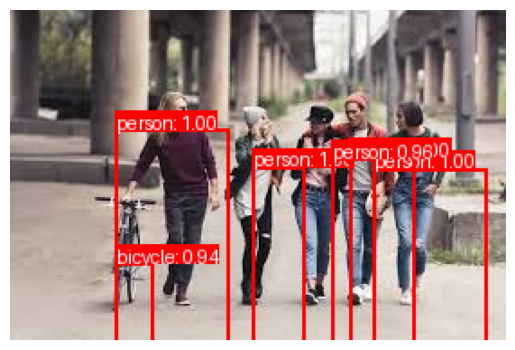

In [9]:
# ---------------------------
# Ejecución ejemplo
# ---------------------------

image_path = "fig/Notebook/Det_img3.jpg"
score_thresh = 0.4

model = load_model()
img_out, boxes, labels, scores = infer_image(model, image_path, score_thresh)

print("\n================= RESULTADOS SSD =================")
for i in range(len(boxes)):
    x1, y1, x2, y2 = boxes[i]
    label_id = labels[i]
    score = scores[i]

    # Evita mostrar detecciones con baja confianza
    if score < score_thresh:
        continue

    # Nombre de clase (si está disponible)
    class_name = (
        COCO_INSTANCE_CATEGORY_NAMES[label_id]
        if label_id < len(COCO_INSTANCE_CATEGORY_NAMES)
        else f"Clase {label_id}"
    )

    print(f"\nDetección {i+1}:")
    print(f"  Clase: {class_name} (ID: {label_id})")
    print(f"  Confianza: {score:.4f}")
    print(f"  Localización [x1, y1, x2, y2]: [{x1:.2f}, {y1:.2f}, {x2:.2f}, {y2:.2f}]")

print("==================================================\n")

# -----------------------------------------------
# Mostrar visualmente y guardar resultado
# -----------------------------------------------plt.figure(figsize=(10, 8))
plt.imshow(np.array(img_out))
plt.axis('off')
plt.show()

# Opcional: guardar resultado
#img_out.save("fig/Latex/ssd_result.png")
#print(f"Guardado: ssd_result.png — detecciones: {len(boxes)} (filtradas por umbral {score_thresh})")

<div style="border: 2px solid #4CAF50; padding: 5px; border-radius: 4px; background-color: #e8f5e9; text-align: center;">
</div>